# Analysis of "10 Best Trading Strategies for 2026" (VT Markets, 3 Aug 2026)

The article is a broker's educational page listing ten strategies for CFD traders (mostly forex, gold and indices on MetaTrader). It is also an advertisement: it ends by promoting a VT Markets account.

This notebook does three things:
1. **Reads the article critically**: which claims have evidence, and which can be checked.
2. **Sorts the ten strategies** by whether our data can test them.
3. **Tests the rule-based ones as written**, on ETH, SOL, BNB, XRP, ADA and DOGE (hourly, 4-hour and daily bars, 2018 to Oct 2026), with fees, and compared with random entries.

**Limits to keep in mind:** the article is written for forex and CFDs, and we only have crypto. Crypto trades 24/7, is far more volatile, and trends harder than EUR/USD, so a result here is *not* a verdict on how the article's strategies work in forex.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from vt_strategies import (COINS, prepare_vt, evaluate_fixed, load_with_volume, rules, benjamini_hochberg)
from trade_sim import atr, DEFAULT_COST

TEST_START = '2024-01-01'
BLUE, ORANGE, AQUA, YELLOW, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#c98500', '#8a8984'
plt.rcParams.update({
    'figure.figsize': (11, 4.5), 'figure.dpi': 110, 'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.spines.top': False,
    'axes.spines.right': False, 'lines.linewidth': 1.6, 'font.size': 10,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
})
pd.set_option('display.width', 250); pd.set_option('display.max_rows', 100); pd.set_option('display.max_colwidth', 90)

## 1. What the article claims, and what can be checked

| Claim in the article | Evidence given | Check |
|---|---|---|
| Daily FX turnover about $9.6 trillion (BIS, April 2025), up 28% from 2022 | Cites the BIS Triennial Survey | A real, checkable source; I did not re-verify the figure. It says nothing about whether any strategy works. |
| 70-85% of retail CFD accounts lose money | "Regulator-mandated broker disclosures" | Consistent with what brokers publish. It is the most important number in the article: most people using these strategies lose. |
| A 1:2 risk/reward with a 45% win rate is profitable | A worked example | Arithmetic is right: 0.45 × 2 − 0.55 × 1 = **+0.35 R per trade before costs**. But it ignores trading costs, which section 4 shows can be large. |
| Risking 10% per trade, 5 straight losses = −41%, needing +69% to recover | Arithmetic | Correct: 0.9⁵ = 0.59 and 1/0.59 − 1 = 69%. |
| "Markets trend roughly 30% of the time" | None | Unsourced, and depends on how "trending" is defined. |
| Swing trading offers "some of the best risk-adjusted returns for part-time traders" | "Recent industry analysis", not named | Unsourced. |
| Scalping is harder in 2026 because of algorithms | None | Plausible, not testable here. |
| "Strategies" such as trend following are "the most reliable" | None | **No backtest, win rate or return figure is given for any of the ten strategies.** |

**The main point:** the article contains good general advice (use stops, risk 1-2% per trade, keep a journal, test on a demo account) but no evidence that any of the ten strategies makes money. The rest of this notebook supplies some.

## 2. Which of the ten can we test?

| # | Strategy | Testable with our data? |
|---|---|---|
| 1 | **Trend following** (50/200 EMA, enter on pullbacks) | **Yes**, tested below |
| 2 | Swing trading (support/resistance, Fibonacci, RSI, 2-10 day holds) | **No clear rules.** Partly covered by our earlier daily tests (divergences, double tops, support/resistance) |
| 3 | **Breakout trading** (range break with rising volume, 1:2 R:R) | **Yes**, tested below |
| 4 | Scalping (1-5 minute bars, 5-15 pips) | **No**: we have no minute data. The hourly results below show how costs eat small moves |
| 5 | Position trading on macro themes (weeks to months) | **No**: needs macro and interest-rate data |
| 6 | **Range trading / mean reversion** (Bollinger Bands, RSI 30/70) | **Yes**, tested below |
| 7 | News and event trading (NFP, CPI) | **No**: no event calendar or tick data |
| 8 | Carry trading (interest-rate differentials) | **No**: an FX concept; crypto spot has no swap income |
| 9 | Price action (pin bars, engulfing, break-and-retest, higher highs and lows) | **Mostly already tested** in earlier notebooks (candlestick patterns, break of structure, fair value gaps, order blocks): no reliable edge beyond momentum |
| 10 | Algorithmic and copy trading | **Not a strategy**: a way of executing one. The article itself says to backtest first |

So **three of the ten can be tested directly**, and a fourth (price action) has already been tested.

## 3. The strategies as coded

The article states some parameters but is vague on entries, so every rule below is written down explicitly and was **fixed before looking at any results. Nothing was tuned.** All trades enter at the next bar's open, with a 0.15% fee-and-slippage cost per side (0.30% round trip). If a bar touches both stop and target, the stop is assumed to hit first.

| Strategy | Entry (long; shorts are the mirror) | Stop / target | Max hold |
|---|---|---|---|
| **Trend following** | EMA50 above EMA200, and the close crosses back above the 20 EMA after closing below it (the "pullback" entry) | 2 ATR / 4 ATR (1:2) | 30 daily, 60 4h, 120 hourly bars |
| **Breakout** | Close above the previous N-bar high (N = 20 days, or 3 days of bars on 4h and hourly, as in the article's example) with volume > 1.5× its 20-bar average ("rising volume"). Also run **without** the volume condition | 2 ATR / 4 ATR (1:2) | 20 daily, 18 4h, 72 hourly bars |
| **Range / mean reversion** | Close below the lower Bollinger Band (20, 2) and RSI(14) < 30. A second version also requires ADX(14) < 20, to "confirm range integrity" | 2 ATR / 3 ATR (1:1.5) | 10 daily, 12 4h, 24 hourly bars |

**How each is judged:** the average net return per trade, compared with **random entries that obey the same regime, direction and exit rules** (so a strategy is not credited for simply trading in a rising market). The p-value is from a permutation test, and the **q-value corrects it for the 30 strategy variants tested**. With nothing tuned, the earlier (before 2024) and recent (2024 onward) periods are both independent checks.

In [2]:
data, res = {}, []
for tf in ('daily', '4h', 'hourly'):
    data[tf] = prepare_vt(COINS, tf)
    pats = sorted(set(p for c in data[tf].values() for p in c['masks']))
    for pat in pats:
        rows, _ = evaluate_fixed(data[tf], pat, -1 if 'short' in pat else 1, tf, TEST_START, n_perm=300)
        res += rows
res = pd.DataFrame(res)
res['family'] = res['pattern'].str.split('_').str[0]
sig = pd.concat([c['events'] for c in data['daily'].values()])
print(len(res.query("period == 'recent'")), 'strategy variants evaluated;', len(COINS), 'coins; signals on daily bars:', len(sig))

30 strategy variants evaluated; 6 coins; signals on daily bars: 4470


## 4. Does the article's win-rate arithmetic survive trading costs?

In [3]:
rows = []
for tf in ('daily', '4h', 'hourly'):
    a = np.median(np.concatenate([(c['atr'] / c['ohlc']['close'].to_numpy())[200:] for c in data[tf].values()]))
    for fam, (s, t) in (('trend / breakout (stop 2 ATR, target 4 ATR)', (2, 4)), ('mean reversion (stop 2 ATR, target 3 ATR)', (2, 3))):
        cost = 2 * DEFAULT_COST
        be0 = s / (s + t)
        be = (s * a + cost) / ((s + t) * a)
        rows.append(dict(timeframe=tf, strategy=fam, median_ATR_pct=100 * a, stop_pct=100 * s * a, round_trip_cost_pct=100 * cost,
                         breakeven_win_rate_before_costs=100 * be0, breakeven_win_rate_after_costs=100 * be))
be = pd.DataFrame(rows)
display(be.round(1))

,timeframe,strategy,median_ATR_pct,stop_pct,round_trip_cost_pct,breakeven_win_rate_before_costs,breakeven_win_rate_after_costs
0,daily,"trend / breakout (stop 2 ATR, target 4 ATR)",6.3,12.5,0.3,33.3,34.1
1,daily,"mean reversion (stop 2 ATR, target 3 ATR)",6.3,12.5,0.3,40.0,41.0
2,4h,"trend / breakout (stop 2 ATR, target 4 ATR)",2.4,4.8,0.3,33.3,35.4
3,4h,"mean reversion (stop 2 ATR, target 3 ATR)",2.4,4.8,0.3,40.0,42.5
4,hourly,"trend / breakout (stop 2 ATR, target 4 ATR)",1.1,2.3,0.3,33.3,37.7
5,hourly,"mean reversion (stop 2 ATR, target 3 ATR)",1.1,2.3,0.3,40.0,45.3


For a 1:2 trade the article's example is right that you only need to win about **33%** of trades to break even **before costs**, so a 45% win rate clears it easily. After the 0.30% round-trip cost used here, break-even rises to **34% on daily, 35% on 4-hour and 38% on hourly** bars (median ATR is about 6.3%, 2.4% and 1.1% of price on those bars, so costs take a bigger slice of each risk unit on shorter bars). For the 1:1.5 range-trading setup it rises to **41%, 43% and 45%**. The hourly 1:2 strategies below mostly win only 32-37% of trades, under that line. Scalping on 1-5 minute bars cannot be tested here.

## 5. Results: the article's strategies as written, 2024 onward

In [4]:
r = res[res['period'] == 'recent'].copy()
r['q_value'] = benjamini_hochberg(r['p_value'].to_numpy())
r['label'] = r['tf'] + ' ' + r['pattern']
show = r.sort_values('avg_net_pct', ascending=False)[['tf', 'pattern', 'n', 'win_rate', 'avg_gross_pct', 'avg_net_pct', 'random_net_pct',
                                                     'profit_factor', 'p_value', 'q_value', 'coins_pos']]
print(f"{int((r['avg_net_pct'] > 0).sum())} of {len(r)} variants made money after costs; {int((r['q_value'] < 0.1).sum())} pass the multiple-testing correction (q < 0.10)")
show.reset_index(drop=True).round(3)

7 of 30 variants made money after costs; 0 pass the multiple-testing correction (q < 0.10)


,tf,pattern,n,win_rate,avg_gross_pct,avg_net_pct,random_net_pct,profit_factor,p_value,q_value,coins_pos
0,daily,meanrev_long_range,4,1.000,5.684,5.384,-2.447,inf,0.047,0.242,2
1,daily,breakout_short_vol,74,0.500,2.081,1.781,1.360,1.352,0.362,0.776,5
2,daily,breakout_long_novol,131,0.473,1.672,1.372,-1.341,1.257,0.010,0.242,5
3,daily,meanrev_short_range,24,0.500,1.494,1.194,-0.688,1.285,0.183,0.526,4
4,daily,trend_short,85,0.412,1.267,0.967,-0.404,1.178,0.193,0.526,5
5,daily,breakout_long_vol,106,0.434,0.943,0.643,-1.389,1.110,0.066,0.249,5
6,4h,trend_short,489,0.401,0.486,0.186,0.086,1.065,0.362,0.776,3
7,hourly,meanrev_long_range,205,0.459,0.226,-0.074,-0.372,0.933,0.056,0.242,4
8,4h,breakout_long_novol,840,0.401,0.184,-0.116,-0.438,0.951,0.030,0.242,2
9,hourly,breakout_short_vol,1109,0.369,0.168,-0.132,-0.152,0.925,0.419,0.785,3


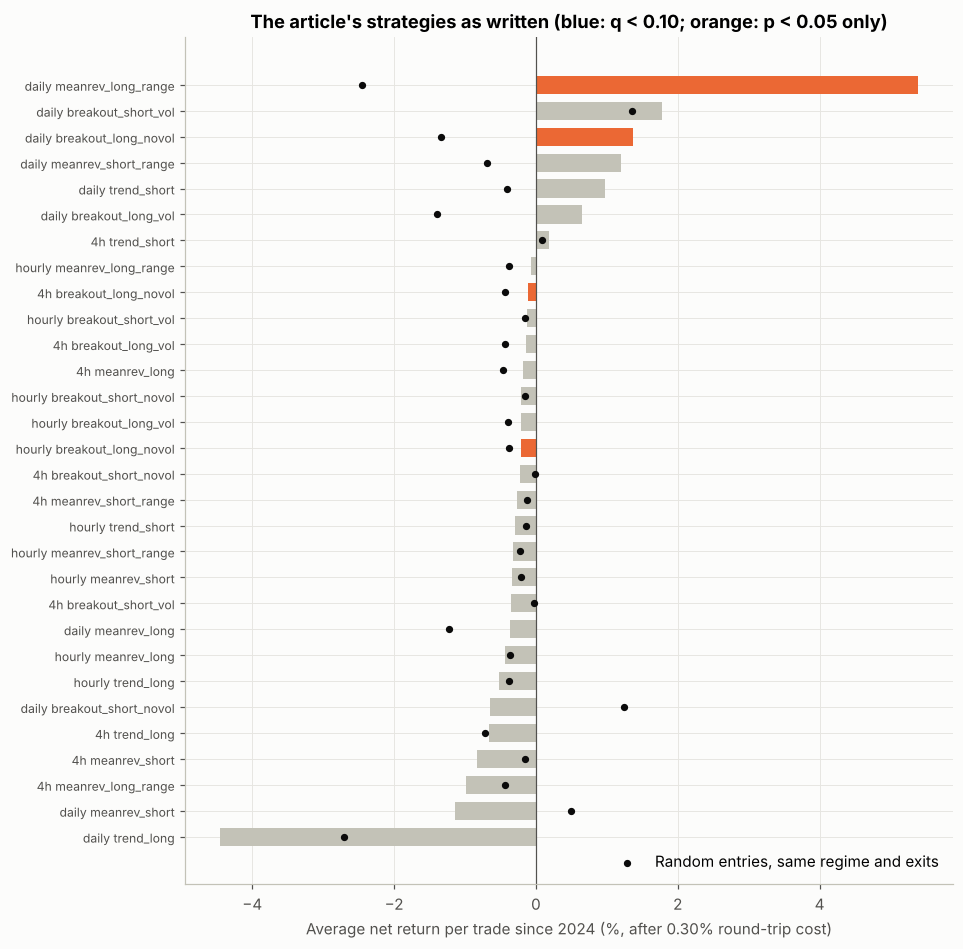

In [5]:
v = r.sort_values('avg_net_pct')
fig, ax = plt.subplots(figsize=(9, 0.28 * len(v) + 1.6))
colors = [BLUE if q < 0.1 else (ORANGE if p < 0.05 else '#c3c2b7') for p, q in zip(v['p_value'], v['q_value'])]
y = np.arange(len(v))
ax.barh(y, v['avg_net_pct'], color=colors, height=0.7)
ax.scatter(v['random_net_pct'], y, color='#0b0b0b', s=14, zorder=3, label='Random entries, same regime and exits')
ax.axvline(0, color='#52514e', lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(v['label'], fontsize=8)
ax.set_xlabel('Average net return per trade since 2024 (%, after 0.30% round-trip cost)')
ax.set_title('The article\'s strategies as written (blue: q < 0.10; orange: p < 0.05 only)')
ax.legend(frameon=False, loc='lower right'); plt.show()

### Same strategies in the earlier period (before 2024): do the results repeat?

In [6]:
w = res.pivot_table(index=['tf', 'pattern'], columns='period', values=['n', 'win_rate', 'avg_net_pct', 'p_value'])
w.columns = [f'{a}_{b}' for a, b in w.columns]
w['positive_in_both'] = (w['avg_net_pct_earlier'] > 0) & (w['avg_net_pct_recent'] > 0)
print('Share of variants with a positive average net return:  before 2024 %.0f%%,  since 2024 %.0f%%' %
      (100 * (w['avg_net_pct_earlier'] > 0).mean(), 100 * (w['avg_net_pct_recent'] > 0).mean()))
print('Win rate range across all variants: %.0f%% to %.0f%%; share with a win rate of 45%% or more: %.0f%%' %
      (100 * res['win_rate'].min(), 100 * res['win_rate'].max(), 100 * (res['win_rate'] >= 0.45).mean()))
print('\nPositive in both periods:')
w[w['positive_in_both']][['n_earlier', 'avg_net_pct_earlier', 'p_value_earlier', 'n_recent', 'avg_net_pct_recent', 'p_value_recent']].round(3)

Share of variants with a positive average net return:  before 2024 23%,  since 2024 23%
Win rate range across all variants: 25% to 100%; share with a win rate of 45% or more: 22%

Positive in both periods:


n_earlier  avg_net_pct_earlier  p_value_earlier  n_recent  avg_net_pct_recent  p_value_recent
tf    pattern                                                                                                           
daily breakout_long_novol      266.0                2.109            0.017     131.0               1.372           0.010
      breakout_long_vol        198.0                2.465            0.013     106.0               0.643           0.066
      trend_short              141.0                1.973            0.206      85.0               0.967           0.193

## 6. Trend following, taken literally: "buy when the 50 EMA is above the 200 EMA"
The article's first strategy is described as holding a bias with the EMA50/EMA200 relationship. Here it is as a position held all the time (next-bar execution, 0.15% per side on each flip), daily bars, six coins. **Long/short** goes short when EMA50 < EMA200; **long/flat** goes to cash instead. Compared with simply buying and holding. Returns and drawdowns are in log percentage points summed over the period.

In [7]:
rows = []
for s in COINS:
    o = load_with_volume(s, 'daily'); c = o['close']; lr = np.log(c).diff()
    pos = pd.Series(np.where(c.ewm(span=50, adjust=False).mean() > c.ewm(span=200, adjust=False).mean(), 1.0, -1.0), index=c.index)
    pos[:200] = 0
    for name, p in (('long/short', pos), ('long/flat', pos.clip(lower=0)), ('buy and hold', pd.Series(1.0, index=c.index))):
        held = p.shift(1).fillna(0); flips = held.diff().abs().fillna(0)
        net = held * lr - flips * DEFAULT_COST
        for per, m in (('before 2024', c.index < TEST_START), ('2024 onward', c.index >= TEST_START)):
            eq = net[m].cumsum()
            rows.append(dict(coin=s[:-4], rule=name, period=per, total_pct=100 * net[m].sum(), worst_drawdown_pct=100 * (eq - eq.cummax()).min()))
ema = pd.DataFrame(rows)
tbl = ema.groupby(['period', 'rule'])[['total_pct', 'worst_drawdown_pct']].mean().round(0)
display(tbl)
piv = ema.pivot_table(index=['period', 'coin'], columns='rule', values='total_pct')
beat = pd.DataFrame({'coins beating buy and hold (of 6)': {(per, rule): int((piv.loc[per][rule] > piv.loc[per]['buy and hold']).sum()) for per in ('before 2024', '2024 onward') for rule in ('long/short', 'long/flat')}})
beat

total_pct  worst_drawdown_pct
period      rule                                       
2024 onward buy and hold       14.0              -146.0
            long/flat          10.0               -93.0
            long/short          6.0              -135.0
before 2024 buy and hold      197.0              -249.0
            long/flat         216.0              -159.0
            long/short        215.0              -242.0

coins beating buy and hold (of 6)
before 2024 long/short                                  5
            long/flat                                   4
2024 onward long/short                                  2
            long/flat                                   2

## 7. Price action (strategy 9): what we already know
This was tested in earlier notebooks on the same six coins, with the same fees and random-entry comparison:
- **Candlestick patterns** (engulfing, pin bars/hammers, doji, morning and evening stars): no better than random entries on any coin or timeframe.
- **Break of structure / higher highs and lows**: positive for bullish breaks, but a plain "new 20-day high" does about as well. It is momentum, and it only worked in bull markets (negative in 2022).
- **Break-and-retest**, fair value gaps and order blocks: no consistent edge once momentum is accounted for.

## Conclusion

**The article gives sound general advice but no evidence that its strategies make money, and when the three rule-based ones are coded as written and tested on crypto, they mostly lose after costs.**

**What the article gets right**
- Risk management: use stops, risk 1-2% per trade, keep a journal, test on a demo account first. The arithmetic it shows (10% losses compounding to −41%) is correct.
- Its most important number: **70-85% of retail CFD accounts lose money.** Nothing in the article explains why following these ten strategies would put you in the other 15-30%.
- It admits some strategies are hard (scalping against algorithms) and that none is a guarantee.

**What it does not do:** give a win rate, backtest or return for any of the ten strategies. It is a broker's page that ends by promoting an account.

**What our tests found** (six coins, fees included, nothing tuned, 30 variants):
- **Only 7 of 30 variants made money since 2024, and none passes the correction for testing many variants** (all q ≥ 0.24). The same share (23%) made money in the earlier period.
- **Trend following (strategy 1, "the most reliable"):** the long side lost money in **all six** timeframe and period combinations (daily −4.5% per trade since 2024). The short side was positive on daily bars (+1.0% since 2024, +2.0% before) but not statistically significant.
- **Literal EMA50/200 rule held as a position:** before 2024 it slightly beat buy-and-hold (+215% vs +197% on average, 4-5 of 6 coins); since 2024 it did not (+10% vs +14%, 2 of 6 coins). It did cut the worst drawdown by about a third, which is a real benefit, but it did not add return.
- **Breakout (strategy 3):** daily long breakouts are the one consistent positive: **+2.1% per trade before 2024 and +1.4% since** (131 recent trades, 5 of 6 coins, beating random entries at p ≈ 0.01). This is the same momentum effect found in the earlier notebooks. The article's "rising volume" condition **did not help** (+0.6% with it, +1.4% without). On 4-hour and hourly bars breakouts beat random entries but still **lost money after costs**.
- **Range trading / mean reversion (strategy 6):** negative on nearly every timeframe. The one big positive bar (daily, with the range filter) is just **4 trades**. Do not read anything into it.
- **Costs matter more on short timeframes:** after a 0.30% round-trip cost, a 1:2 trade needs a win rate of 34% on daily bars, 35% on 4-hour and **38% on hourly**; hourly 1:1.5 range trades need **45%**. Hourly 1:2 strategies here won only 32-37% of trades. The article's "45% win rate is profitable" holds, but its example ignores costs.
- **Price action (strategy 9)** was already tested: candlestick patterns and structure breaks show no reliable edge beyond momentum.
- **Not testable here:** swing trading (no rules given), scalping (needs minute data), macro position trading, news trading, carry, copy trading.

**Caveats**
- The article is vague on entries; the rules here are my reading of it. Other readings could behave differently.
- It is written for forex and CFDs, and we only have crypto, which is far more volatile (median daily ATR is 6.3% of price). A result here does not show how the strategies work on EUR/USD.
- Costs assume crypto exchange fees (0.15% per side). A CFD broker's spreads, swaps and commissions would differ.
- Trades on different coins happen on the same days, so the p-values are somewhat optimistic.

**Bottom line:** nothing in this article changes our conclusion. Of everything tested so far, the only thing that has passed our strictest test is still shorting after a daily MACD bearish divergence. If you want to test the article's strategies in the markets they were written for (EUR/USD, gold, indices), that needs forex data, which we don't have yet.